# Fotogrametría: escala, desplazamiento del relieve y paralaje

La fotogrametría es la ciencia de obtener medidas confiables a partir de fotografías. Una fotografía aérea vertical es una proyección central: todos los rayos de luz pasan por el centro óptico de la cámara, y no una proyección ortogonal como la de un mapa. De esa diferencia nacen las dos propiedades que estudia este capítulo, la variación de la escala y el desplazamiento del relieve, y de la combinación de dos fotos nace la posibilidad de medir alturas con el paralaje {cite}`lillesand2015,pacheco2006`.

## Escala de una fotografía vertical

La escala de una fotografía es la relación entre una distancia en la foto y la distancia correspondiente en el terreno. Por semejanza de triángulos, para una foto vertical tomada con una cámara de distancia focal $f$ a una altura $H$ sobre el nivel del mar, un punto ubicado a una elevación $h$ tiene una escala

$$E = \frac{f}{H - h}.$$

En terreno plano la escala es constante, pero en terreno montañoso cambia de un punto a otro: las cimas, más cerca de la cámara, quedan a mayor escala que los valles. Por eso se habla de una escala media, calculada con la elevación media del terreno. La escala también se puede obtener comparando una distancia medida en la foto con la misma distancia medida en un mapa de escala conocida.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 100

f = 0.1524          # m
H = 4500.0          # altura de vuelo sobre el nivel del mar (m)
for lugar, h in [('fondo del valle del Cauca', 600), ('ladera media', 1500), ('cima', 2600)]:
    print(f'{lugar:28s} h = {h:5.0f} m  -> escala 1:{(H-h)/f:,.0f}')
h_media = (600 + 2600) / 2
print(f'Escala media: 1:{(H-h_media)/f:,.0f}')

# escala a partir de una distancia foto-mapa
d_foto = 0.0735     # m medidos en la foto
d_mapa = 0.094      # m medidos en un mapa 1:25 000
D = d_mapa * 25000
print(f'Distancia en el terreno {D:.0f} m -> escala de la foto 1:{D/d_foto:,.0f}')

fondo del valle del Cauca    h =   600 m  -> escala 1:25,591
ladera media                 h =  1500 m  -> escala 1:19,685
cima                         h =  2600 m  -> escala 1:12,467
Escala media: 1:19,029
Distancia en el terreno 2350 m -> escala de la foto 1:31,973


La escala espacial no debe confundirse con la extensión del fenómeno estudiado. En geomorfología se habla también de escala para referirse al tamaño del área o del proceso que se analiza; un mapa a gran escala, como 1:5000, muestra un área pequeña con mucho detalle, y uno a pequeña escala, como 1:500 000, un área grande con poco detalle.

## Desplazamiento del relieve

En una proyección central, un objeto con altura aparece desplazado radialmente desde el punto nadir de la foto (en una foto vertical, prácticamente el punto principal): la cima de una torre o de un cerro se ve más lejos del centro que su base. El desplazamiento $d$ medido en la foto es

$$d = \frac{r\,h}{H},$$

donde $r$ es la distancia radial desde el nadir hasta la cima del objeto en la foto, $h$ la altura del objeto sobre su base y $H$ la altura de vuelo sobre la base. El desplazamiento es nulo en el nadir y crece hacia los bordes de la foto, y crece con la altura del objeto. Este efecto deforma los mapas trazados directamente sobre las fotos y es lo que corrige la ortorrectificación, pero también es el que permite la visión estereoscópica. Despejando, la misma fórmula sirve para medir alturas de objetos aislados: $h = d\,H / r$.

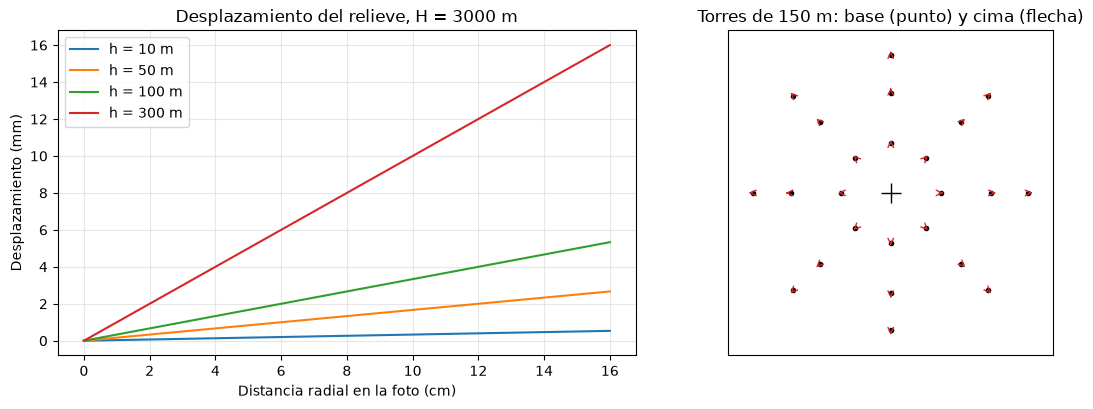

Ejemplo: d = 2.1 mm, r = 8.62 cm, H = 3000 m -> altura del objeto 73 m


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
r = np.linspace(0, 0.16, 100)
for hh in [10, 50, 100, 300]:
    ax[0].plot(r * 100, r * hh / 3000 * 1000, label=f'h = {hh} m')
ax[0].set_xlabel('Distancia radial en la foto (cm)'); ax[0].set_ylabel('Desplazamiento (mm)')
ax[0].set_title('Desplazamiento del relieve, H = 3000 m'); ax[0].legend(); ax[0].grid(alpha=0.3)

# esquema en planta: torres en una foto
ax[1].plot(0, 0, 'k+', ms=15)
for ang in np.radians(np.arange(0, 360, 45)):
    for rr in [0.04, 0.08, 0.11]:
        xb, yb = rr * np.cos(ang), rr * np.sin(ang)
        d = rr * 150 / 3000
        ax[1].annotate('', xy=(xb + d * np.cos(ang), yb + d * np.sin(ang)), xytext=(xb, yb),
                       arrowprops=dict(arrowstyle='->', color='tab:red'))
        ax[1].plot(xb, yb, 'ko', ms=3)
ax[1].set_aspect('equal'); ax[1].set_xlim(-0.13, 0.13); ax[1].set_ylim(-0.13, 0.13)
ax[1].set_title('Torres de 150 m: base (punto) y cima (flecha)')
ax[1].set_xticks([]); ax[1].set_yticks([])
plt.tight_layout(); plt.show()

d, r_cima, H_base = 0.0021, 0.0862, 3000
print(f'Ejemplo: d = {d*1000:.1f} mm, r = {r_cima*100:.2f} cm, H = {H_base} m -> altura del objeto {d*H_base/r_cima:.0f} m')

## Paralaje

El paralaje es el desplazamiento aparente de la posición de un objeto causado por un cambio en el punto de observación. En un par estereoscópico cada punto del terreno aparece en las dos fotos, y su posición a lo largo de la dirección de vuelo cambia de una foto a la otra. El paralaje absoluto (o paralaje x) de un punto es la diferencia entre sus coordenadas $x$ en las dos fotos, medidas desde el punto principal de cada una a lo largo de la línea de vuelo, $p = x_1 - x_2$. Los puntos más altos, más cercanos a la cámara, tienen mayor paralaje que los bajos.

La relación entre el paralaje y la elevación sale, de nuevo, de triángulos semejantes: $p = f B / (H - h)$, con $B$ la base aérea. La diferencia de paralaje $\Delta p$ entre dos puntos, el paralaje relativo, permite calcular su diferencia de altura:

$$\Delta h = \frac{H' \, \Delta p}{p_b + \Delta p},$$

donde $H'$ es la altura de vuelo sobre el punto más bajo y $p_b$ su paralaje absoluto, que en la práctica se aproxima por la base aérea medida en la foto. La diferencia de paralaje se mide con una barra de paralaje (un estereómetro) sobre el modelo estereoscópico, y con ella se pueden levantar perfiles, medir espesores de estratos o alturas de escarpes, y, de forma sistemática, construir modelos digitales de elevación, que es lo que hacen los programas de fotogrametría digital y de estructura a partir del movimiento (SfM) con fotos de dron.

In [3]:
f, B = 0.1524, 1840.0           # m
H_vuelo = 4600.0                # sobre el nivel del mar
def paralaje(h):
    return f * B / (H_vuelo - h)
h_valle, h_cima = 1450.0, 1720.0
p_valle, p_cima = paralaje(h_valle), paralaje(h_cima)
dp = p_cima - p_valle
dh = (H_vuelo - h_valle) * dp / (p_valle + dp)
print(f'Paralaje del valle {p_valle*1000:.2f} mm, de la cima {p_cima*1000:.2f} mm, diferencia {dp*1000:.2f} mm')
print(f'Diferencia de altura recuperada: {dh:.1f} m (real {h_cima-h_valle:.0f} m)')

# sensibilidad: error de 0.05 mm en la medida del paralaje
err = 0.05e-3
dh_err = (H_vuelo - h_valle) * (dp + err) / (p_valle + dp + err) - dh
print(f'Un error de 0.05 mm en la diferencia de paralaje produce un error de {dh_err:.1f} m en la altura')

Paralaje del valle 89.02 mm, de la cima 97.37 mm, diferencia 8.35 mm
Diferencia de altura recuperada: 270.0 m (real 270 m)
Un error de 0.05 mm en la diferencia de paralaje produce un error de 1.5 m en la altura


La celda siguiente simula el procedimiento completo sobre un perfil topográfico: calcula el paralaje que tendría cada punto del perfil en un par estereoscópico, le agrega un error de medida como el de un operador con barra de paralaje y reconstruye las alturas. Muestra que la fotogrametría convencional recupera bien la forma del terreno, con errores de pocos metros que dependen de la precisión de la medida y de la relación base-altura.

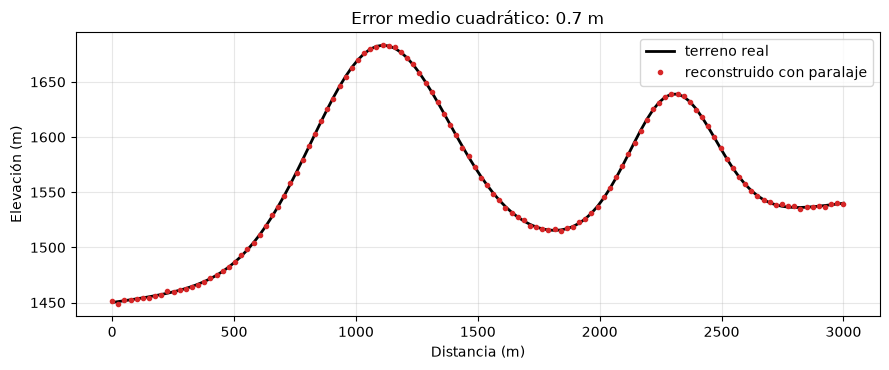

In [4]:
rng = np.random.default_rng(3)
xp = np.linspace(0, 3000, 120)
perfil = 1450 + 200 * np.exp(-((xp - 1100) / 400)**2) + 120 * np.exp(-((xp - 2300) / 250)**2) + 0.03 * xp
p = paralaje(perfil) + rng.normal(0, 0.02e-3, xp.size)
p0 = paralaje(perfil[0])
h_rec = perfil[0] + (H_vuelo - perfil[0]) * (p - p0) / p
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(xp, perfil, 'k', lw=2, label='terreno real')
ax.plot(xp, h_rec, '.', color='tab:red', label='reconstruido con paralaje')
ax.set_xlabel('Distancia (m)'); ax.set_ylabel('Elevación (m)'); ax.legend(); ax.grid(alpha=0.3)
ax.set_title(f'Error medio cuadrático: {np.sqrt(np.mean((h_rec-perfil)**2)):.1f} m')
plt.tight_layout(); plt.show()

## De la fotografía al ortofotomosaico

Para usar las fotografías como un mapa hay que eliminar el desplazamiento del relieve y la inclinación de la cámara. La ortorrectificación lo hace con un modelo digital de elevación y con la orientación de cada foto (posición y actitud de la cámara), y produce una ortofoto, una imagen con la geometría de un mapa. Un mosaico de ortofotos es un ortofotomosaico, el producto base de la cartografía catastral y temática actual. Con drones y la técnica de estructura a partir del movimiento, el mismo proceso, desde la planeación del vuelo hasta el ortofotomosaico y el modelo digital de superficie, está hoy al alcance de cualquier proyecto de geología.

## Para profundizar

Los conceptos de este capítulo se desarrollan en el capítulo 3 de {cite}`lillesand2015` y en el manual de {cite:t}`pacheco2006`, que contiene ejercicios resueltos de escala, desplazamiento y paralaje. Los talleres de fotogrametría y de cálculo del curso aplican estas fórmulas a fotografías reales del IGAC.